# Difração de Raios X: Atividade I

Análise do padrão de DRX de um metal com estrutura cúbica.

**Etapas do roteiro cobertas neste notebook**

| Item | O que é feito | Seção |
|---|---|---|
| I | Plotar o difratograma | 3 |
| II | Normalizar as intensidades (pico mais intenso = 100%) | 4 |
| III | Determinar 2θ e intensidade relativa de cada pico | 5 |
| IV | Calcular a distância interplanar $d_{hkl}$ (Lei de Bragg) | 6 |
| V | Determinar o tipo de rede cúbica (CS, CCC ou CFC) | 7 |
| VI e VII | Indexar os picos com os índices de Miller (hkl) | 8 e 9 |
| VIII | Calcular o parâmetro de rede $a$, a média e o erro | 8 |

---

### Fundamentos: o que é um difratograma?

Os raios X são ondas eletromagnéticas com comprimento de onda $\lambda$ da ordem de 0,1 nm, a mesma ordem de grandeza das distâncias entre os planos de átomos de um cristal. Por isso o cristal funciona como uma **rede de difração**: os raios espalhados por planos atômicos paralelos interferem entre si. A interferência é construtiva apenas em ângulos bem definidos, e é nesses ângulos que surgem os picos.

No **difratômetro** (geometria Bragg-Brentano θ–2θ), a amostra policristalina (pó) é irradiada por um feixe monocromático. A fonte e o detector se movem de modo que o ângulo de incidência θ seja sempre igual ao de reflexão. O detector registra a intensidade em função de **2θ**, que é o ângulo entre o feixe incidente e o difratado. Como a amostra tem milhares de grãos com orientações aleatórias, sempre há grãos com cada família de planos (hkl) na orientação certa para difratar.

O **difratograma** é o gráfico intensidade × 2θ. Ele contém:
- a **posição** dos picos (2θ), que depende das distâncias interplanares e portanto da geometria da célula unitária;
- a **intensidade** dos picos, que depende dos átomos presentes e de suas posições na célula (fator de estrutura), da multiplicidade dos planos, de fatores geométricos e de eventual textura;
- a **largura** dos picos, ligada ao tamanho de cristalito, às microdeformações e ao instrumento.

In [11]:
# ---------------------------------------------------------------
# Bibliotecas utilizadas
# ---------------------------------------------------------------
import pandas as pd              # leitura do CSV e montagem das tabelas (DataFrames)
import matplotlib.pyplot as plt  # geração dos gráficos
import numpy as np               # cálculos numéricos com vetores (seno, raiz, radianos...)

# Faz os gráficos aparecerem dentro do próprio notebook, logo abaixo da célula
%matplotlib inline

## 1. Leitura dos dados

O arquivo contém duas colunas: o ângulo **2θ** (em graus) e a **intensidade** medida pelo detector (em contagens). O passo de varredura é de **0,1°**, de 0,1° até 180°, o que dá 1800 pontos.

**Atenção ao formato:** o CSV usa vírgula como separador de colunas **e** vírgula como separador decimal (padrão brasileiro). Os números decimais vêm entre aspas, por exemplo `"31,3"`, e é isso que permite ao `pandas` distinguir as duas vírgulas. Ajuste `ARQUIVO` para o caminho do arquivo no seu computador.

In [12]:
# Caminho do arquivo de dados. O prefixo r"..." (raw string) faz o Python tratar
# as barras invertidas "\" do caminho do Windows como texto comum.
ARQUIVO = r"C:\Users\bruno\OneDrive\Visual Studio Code\2026.3\Dados.csv"

# Leitura do CSV:
#   sep=","      -> colunas separadas por vírgula
#   decimal=","  -> números como "31,3" são lidos como 31.3
#   encoding     -> codificação do arquivo (o cabeçalho tem caracteres especiais: "Ângulo 2Ɵ")
df = pd.read_csv(ARQUIVO, sep=",", decimal=",", encoding="utf-8")

# Renomeia as colunas com nomes curtos e sem acentos, mais fáceis de usar no código
df.columns = ["2theta", "I"]

# Garante que a intensidade seja número real (float), necessário para a normalização
df["I"] = df["I"].astype(float)

# Conferência rápida: quantidade de pontos e faixa angular medida
print(f"{len(df)} pontos, 2θ de {df['2theta'].min()}° a {df['2theta'].max()}°")
df.head()   # mostra as 5 primeiras linhas

1800 pontos, 2θ de 0.1° a 180.0°


,2theta,I
0,0.1,76.0
1,0.2,76.0
2,0.3,76.0
3,0.4,76.0
4,0.5,76.0


## 2. Detecção dos picos e função de plotagem

### Como um pico é identificado

Fora dos picos, o difratograma tem uma **linha de base** (o *background*), que aqui vale 76 contagens. Ela vem do espalhamento incoerente, da fluorescência da amostra e do ruído do detector, e **não** carrega informação cristalográfica.

Um ponto $i$ é considerado um **pico** quando cumpre três condições:
1. é um **máximo local**, ou seja, maior que o vizinho da esquerda e maior ou igual ao da direita: $I_{i-1} < I_i \geq I_{i+1}$;
2. está **acima de um limiar**, que aqui é o fundo mais 5% da altura do maior pico. Isso descarta flutuações pequenas da linha de base;
3. está **separado de outros picos** por pelo menos 10 pontos (1°). Se houver dois máximos mais próximos que isso, fica apenas o mais alto.

A posição do pico é tomada como o ângulo de **intensidade máxima**. Como o passo é de 0,1°, a incerteza na posição é de cerca de ±0,05° em 2θ.

### Função de plotagem

Para não repetir código, a função `plotar_difratograma` desenha qualquer versão do difratograma (bruta ou normalizada), marca o ângulo de cada pico e salva a figura em PNG com 300 dpi, uma resolução adequada para o relatório.

In [13]:
def find_peaks(y, height, distance=10):
    '''
    Encontra os picos de um sinal y (feito só com numpy, sem scipy).

    Parâmetros
    ----------
    y        : vetor de intensidades
    height   : intensidade mínima para um ponto ser considerado pico
    distance : separação mínima (em número de pontos) entre dois picos

    Retorna
    -------
    Vetor com os ÍNDICES dos picos, em ordem crescente de 2θ, e um dicionário
    vazio (mantido apenas para ter o mesmo formato de saída do scipy).
    '''
    # Índices internos do vetor (o primeiro e o último ponto não têm dois vizinhos)
    i = np.arange(1, len(y) - 1)

    # Candidatos: máximos locais acima do limiar.
    # y[i] > y[i-1]   -> maior que o vizinho da esquerda
    # y[i] >= y[i+1]  -> maior ou igual ao da direita (o ">=" trata picos de topo
    #                    plano, como em 134,2° e 134,3°, que têm a mesma intensidade)
    cand = i[(y[i] > y[i - 1]) & (y[i] >= y[i + 1]) & (y[i] > height)]

    # Filtro de distância: percorre os candidatos do MAIS ALTO para o MAIS BAIXO
    # e só aceita um candidato se ele estiver longe de todos os picos já aceitos.
    picos = []
    for p in cand[np.argsort(-y[cand])]:      # argsort(-y) ordena em ordem decrescente
        if all(abs(p - q) >= distance for q in picos):
            picos.append(p)

    return np.array(sorted(picos)), {}


def plotar_difratograma(x, y, ylabel, titulo, salvar=None):
    '''
    Plota o difratograma, marca o ângulo 2θ de cada pico e (opcionalmente) salva a figura.
    Retorna os índices dos picos encontrados.
    '''
    # Limiar de detecção: linha de base + 5% da altura útil do maior pico
    fundo = y.min()
    picos, _ = find_peaks(y, height=fundo + 0.05 * (y.max() - fundo), distance=10)

    # Cria a figura (largura x altura, em polegadas) e desenha a curva
    fig, ax = plt.subplots(figsize=(12, 5.5))
    ax.plot(x, y, color="#1f4e79", lw=1.2)

    # Escreve o valor de 2θ acima de cada pico.
    # A altura do rótulo alterna entre 6 e 18 pontos para que picos próximos
    # (ex.: 85,5° e 88,3°) não tenham os textos sobrepostos.
    for k, p in enumerate(picos):
        dy = 6 if k % 2 == 0 else 18
        ax.annotate(f"{x[p]:.1f}°", xy=(x[p], y[p]), xytext=(0, dy),
                    textcoords="offset points", ha="center", fontsize=9)

    # Eixos, título e grade (r"$2\theta$" é escrito em notação LaTeX)
    ax.set_xlabel(r"$2\theta$ (graus)", fontsize=12)
    ax.set_ylabel(ylabel, fontsize=12)
    ax.set_title(titulo, fontsize=13)
    ax.set_xlim(x.min(), x.max())
    ax.set_ylim(0, y.max() * 1.12)     # 12% de folga no topo para caber os rótulos
    ax.grid(alpha=0.3)
    fig.tight_layout()

    if salvar:                          # salva em PNG de alta resolução para o relatório
        fig.savefig(salvar, dpi=300)
    plt.show()
    return picos

## 3. Difratograma: intensidade bruta (Item I)

A intensidade é dada em contagens, que é o número de fótons registrados pelo detector em cada ângulo. Esse valor absoluto depende de condições experimentais (potência do tubo, tempo de contagem por passo, quantidade de amostra), por isso é expresso em **unidades arbitrárias (u.a.)**.

Cada pico corresponde a uma **família de planos cristalinos (hkl)** que satisfaz a condição de Bragg. Picos em ângulos menores correspondem a planos mais espaçados (d maior).

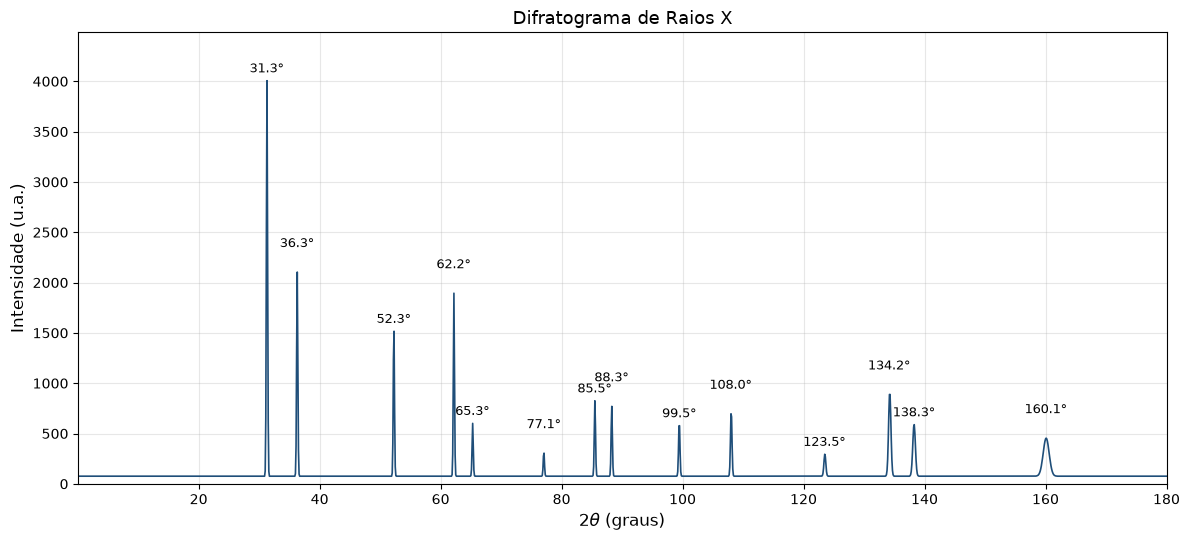

In [14]:
# Converte as colunas do DataFrame em vetores numpy (mais práticos para os cálculos)
x = df["2theta"].to_numpy()   # ângulos 2θ (graus)
y = df["I"].to_numpy()        # intensidades (contagens)

# Plota, detecta os picos e guarda os índices deles na variável "picos"
picos = plotar_difratograma(x, y, "Intensidade (u.a.)", "Difratograma de Raios X",
                            salvar="difratograma.png")

## 4. Difratograma normalizado (Item II)

Como a intensidade absoluta depende das condições de medida, o que se compara com bancos de dados (fichas ICDD/PDF) e com a literatura é a **intensidade relativa**. O pico mais intenso recebe 100% e os demais são expressos como porcentagem dele:

$$I_{rel} = 100 \cdot \frac{I}{I_{max}}$$

A normalização **não altera** a posição nem a forma dos picos, só a escala do eixo vertical.

> *Observação:* aqui a linha de base (76 contagens) não foi subtraída. Se ela for subtraída antes, $I_{rel} = 100\,(I - I_{fundo})/(I_{max} - I_{fundo})$, as intensidades relativas dos picos fracos diminuem um pouco. Vale escolher uma das convenções e indicá-la no relatório.

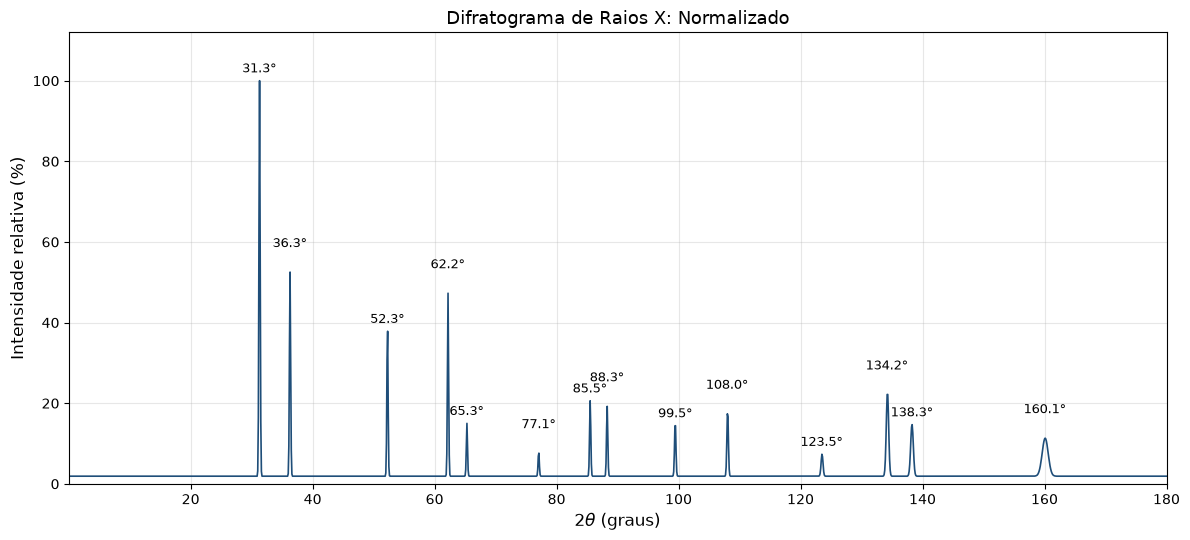

In [15]:
# Normalização: divide todas as intensidades pela máxima e multiplica por 100
y_norm = 100 * y / y.max()

# Plota a versão normalizada. O retorno é descartado com "_" porque os picos
# são os mesmos já encontrados na seção 3.
_ = plotar_difratograma(x, y_norm, "Intensidade relativa (%)",
                        "Difratograma de Raios X: Normalizado",
                        salvar="difratograma_normalizado.png")

## 5. Tabela de picos (Item III)

Para cada pico detectado são registrados a posição 2θ, a intensidade absoluta e a intensidade relativa.

As intensidades relativas **não são todas iguais** porque cada família de planos (hkl) tem:
- um **fator de estrutura** $F_{hkl}$, que soma as ondas espalhadas por todos os átomos da célula;
- uma **multiplicidade** $p$, que é o número de planos equivalentes por simetria. Por exemplo, {111} tem 8 e {200} tem 6;
- um **fator de Lorentz-polarização** e um **fator de espalhamento atômico** $f$, que diminuem com o ângulo.

Simplificando, $I_{hkl} \propto |F_{hkl}|^2 \cdot p \cdot LP(\theta)$. Planos com maior densidade atômica tendem a difratar com mais intensidade.

In [16]:
# Monta a tabela usando os índices dos picos para extrair os valores de cada vetor
tabela = pd.DataFrame({
    "2θ (°)": x[picos],                         # posição de cada pico
    "I (contagens)": y[picos].astype(int),      # intensidade absoluta
    "I relativa (%)": y_norm[picos].round(1),   # intensidade normalizada
})

# Numera os picos a partir de 1 (o padrão do pandas começa em 0)
tabela.index = range(1, len(tabela) + 1)
tabela.index.name = "Pico"
tabela

,2θ (°),I (contagens),I relativa (%)
Pico,,,
1,31.3,4006,100.0
2,36.3,2104,52.5
3,52.3,1516,37.8
4,62.2,1894,47.3
5,65.3,601,15.0
6,77.1,305,7.6
7,85.5,825,20.6
8,88.3,770,19.2
9,99.5,578,14.4


## 6. Distância interplanar: Lei de Bragg (Item IV)

### Teoria

Considere dois planos atômicos paralelos separados pela distância $d$, atingidos por um feixe sob o ângulo θ. A onda refletida pelo segundo plano percorre um caminho **maior** que a refletida pelo primeiro, e essa diferença vale $2d\sin\theta$. Para que as ondas cheguem **em fase** (interferência construtiva), a diferença de caminho tem de ser um número inteiro de comprimentos de onda:

$$n\lambda = 2\,d_{hkl}\,\sin\theta$$

Esta é a **Lei de Bragg**. Usando $n = 1$ (as ordens superiores são tratadas como planos com índices multiplicados, por exemplo a 2ª ordem de (111) equivale a (222)) e isolando $d$:

$$d_{hkl} = \frac{\lambda}{2\sin\theta}$$

**Pontos de atenção**
- O difratograma dá **2θ**, mas a Lei de Bragg usa **θ**, então é preciso dividir por 2.
- As funções trigonométricas do numpy trabalham em **radianos**.
- λ = 0,1541838 nm, a radiação **Cu Kα** usada no ensaio.

Também calculamos $\sin^2\theta$, que será usado na seção 7 para identificar a estrutura.

> *Detalhe numérico:* os cálculos são feitos com os valores completos. O arredondamento (`.round`) é aplicado só na hora de **exibir** a tabela, para não acumular erro nas etapas seguintes.

In [17]:
LAMBDA = 0.1541838  # comprimento de onda da radiação Cu Kα (nm)

# θ em radianos: divide 2θ por 2 e converte de graus para radianos
theta = np.radians(tabela["2θ (°)"].to_numpy() / 2)

# Lei de Bragg (n = 1): d = λ / (2·senθ)
d = LAMBDA / (2 * np.sin(theta))

# sen²θ, usado no teste da estrutura cúbica
sen2 = np.sin(theta) ** 2

# Guarda na tabela (arredondado só para a exibição)
tabela["d (nm)"] = d.round(4)
tabela["sen²θ"] = sen2.round(4)
tabela

,2θ (°),I (contagens),I relativa (%),d (nm),sen²θ
Pico,,,,,
1,31.3,4006,100.0,0.2858,0.0728
2,36.3,2104,52.5,0.2475,0.0970
3,52.3,1516,37.8,0.1749,0.1942
4,62.2,1894,47.3,0.1492,0.2668
5,65.3,601,15.0,0.1429,0.2911
6,77.1,305,7.6,0.1237,0.3884
7,85.5,825,20.6,0.1136,0.4608
8,88.3,770,19.2,0.1107,0.4852
9,99.5,578,14.4,0.1010,0.5825


## 7. Teste da estrutura cúbica (Item V)

### Teoria: de onde vem a razão sen²θ/S

Num cristal **cúbico** de parâmetro de rede $a$, a distância entre os planos (hkl) é

$$d_{hkl} = \frac{a}{\sqrt{h^2+k^2+l^2}} = \frac{a}{\sqrt{S}}, \qquad S = h^2+k^2+l^2$$

Substituindo na Lei de Bragg ($\lambda = 2d\sin\theta$) e elevando ao quadrado:

$$\sin^2\theta = \frac{\lambda^2}{4a^2}\,S \quad\Longrightarrow\quad \frac{\sin^2\theta}{S} = \frac{\lambda^2}{4a^2} = \text{constante}$$

Como λ e $a$ são fixos, a razão $\sin^2\theta / S$ tem de ser **a mesma para todos os picos**, mas **só** se cada pico receber o valor de S correto. O que muda de uma rede para outra é **quais valores de S existem**.

### Regras de extinção (fator de estrutura)

A intensidade de um pico é proporcional a $|F_{hkl}|^2$, onde

$$F_{hkl} = \sum_j f_j \, e^{2\pi i (h x_j + k y_j + l z_j)}$$

e a soma percorre os átomos da célula, nas posições $(x_j, y_j, z_j)$. Para um metal puro (todos os $f_j = f$):

| Estrutura | Átomos na célula | $F_{hkl}$ | Picos presentes | Sequência de S |
|---|---|---|---|---|
| **Cúbica simples (CS)** | (0,0,0) | $f$ | todos os (hkl) | 1, 2, 3, 4, 5, 6, 8, 9, ... (nunca 7) |
| **CCC** | (0,0,0), (½,½,½) | $f\,[1 + e^{i\pi(h+k+l)}]$ | $h+k+l$ **par** ($F=2f$) | 2, 4, 6, 8, 10, 12, 14, 16, ... |
| **CFC** | (0,0,0), (½,½,0), (½,0,½), (0,½,½) | $f\,[1 + e^{i\pi(h+k)} + e^{i\pi(h+l)} + e^{i\pi(k+l)}]$ | h, k, l **todos pares ou todos ímpares** ($F=4f$) | 3, 4, 8, 11, 12, 16, 19, 20, ... |

Quando $F_{hkl} = 0$ as ondas espalhadas pelos átomos da célula se cancelam e o pico **não aparece**, mesmo que o plano exista (é uma **extinção sistemática**). Por isso a CFC, por exemplo, não tem picos (100) nem (110).

A assinatura típica da CFC é a sequência de **pares de picos próximos**: (111)-(200), depois (311)-(222), e assim por diante.

### Procedimento

1. Para cada estrutura, gerar a sequência de valores de S permitidos.
2. Atribuir o 1º valor de S ao 1º pico, o 2º ao 2º, e assim por diante.
3. Calcular $\sin^2\theta/S$ para cada pico.
4. Medir a dispersão com o **coeficiente de variação** $CV = 100\,\sigma/\bar{x}$. A estrutura correta é a que dá o CV mais próximo de zero.

In [18]:
def sequencia_S(regra, n):
    '''
    Gera os n primeiros valores de S = h²+k²+l² permitidos por uma regra de reflexão,
    junto com os planos (hkl) que dão cada valor de S.

    Exemplo: na CFC, S = 27 vem tanto de (333) quanto de (511), que difratam
    no MESMO ângulo; por isso os dois são listados juntos: "(333) / (511)".
    '''
    planos = {}   # dicionário {S: lista de planos (hkl)}
    # Percorre combinações com h >= k >= l >= 0. Isso basta, porque permutações e
    # sinais (ex.: (1-11), (101)) dão o mesmo S e pertencem à mesma família {hkl}.
    for h in range(0, 12):
        for k in range(0, h + 1):
            for l in range(0, k + 1):
                if (h, k, l) != (0, 0, 0) and regra(h, k, l):
                    planos.setdefault(h*h + k*k + l*l, []).append(f"({h}{k}{l})")
    S = sorted(planos)[:n]                       # os n menores valores de S
    return np.array(S), [" / ".join(planos[s]) for s in S]


# Regras de reflexão de cada rede (retornam True se o plano (hkl) difrata)
regras = {
    "CS":  lambda h, k, l: True,                              # todos aparecem
    "CCC": lambda h, k, l: (h + k + l) % 2 == 0,              # soma par
    "CFC": lambda h, k, l: len({h % 2, k % 2, l % 2}) == 1,   # paridades iguais
    # Na CFC, {h%2, k%2, l%2} é o conjunto das paridades: se tiver um único
    # elemento, h, k e l são todos pares (0) ou todos ímpares (1).
}

n = len(sen2)   # número de picos
teste = pd.DataFrame({"2θ (°)": tabela["2θ (°)"], "sen²θ": sen2.round(4)})
resumo = {}

for nome, regra in regras.items():
    S, hkl = sequencia_S(regra, n)          # sequência de S desta estrutura
    razao = sen2 / S                        # sen²θ/S para cada pico
    teste[f"S ({nome})"] = S
    teste[f"sen²θ/S ({nome})"] = razao.round(5)
    # Coeficiente de variação (%): quanto menor, mais constante é a razão
    resumo[nome] = 100 * razao.std() / razao.mean()

display(teste)
for nome, cv in resumo.items():
    print(f"{nome}: variação de sen²θ/S = {cv:.2f} %")

# A estrutura escolhida é a de menor coeficiente de variação
estrutura = min(resumo, key=resumo.get)
print(f"\n→ A razão sen²θ/S é constante para a estrutura {estrutura}")

,2θ (°),sen²θ,S (CS),sen²θ/S (CS),S (CCC),sen²θ/S (CCC),S (CFC),sen²θ/S (CFC)
Pico,,,,,,,,
1,31.3,0.0728,1,0.07277,2,0.03639,3,0.02426
2,36.3,0.0970,2,0.04852,4,0.02426,4,0.02426
3,52.3,0.1942,3,0.06475,6,0.03237,8,0.02428
4,62.2,0.2668,4,0.06670,8,0.03335,11,0.02426
5,65.3,0.2911,5,0.05821,10,0.02911,12,0.02426
6,77.1,0.3884,6,0.06473,12,0.03236,16,0.02427
7,85.5,0.4608,8,0.05760,14,0.03291,19,0.02425
8,88.3,0.4852,9,0.05391,16,0.03032,20,0.02426
9,99.5,0.5825,10,0.05825,18,0.03236,24,0.02427


CS: variação de sen²θ/S = 9.42 %
CCC: variação de sen²θ/S = 8.94 %
CFC: variação de sen²θ/S = 0.04 %

→ A razão sen²θ/S é constante para a estrutura CFC


## 8. Indexação (hkl) e parâmetro de rede (Itens VI a VIII)

### Índices de Miller

Com a estrutura identificada, cada pico recebe o plano (hkl) correspondente ao seu valor de S. Os **índices de Miller** (hkl) são os inversos das interseções do plano com os eixos x, y e z, reduzidos aos menores inteiros. A notação entre chaves, {hkl}, indica a **família** de planos equivalentes por simetria.

### Parâmetro de rede

Isolando $a$ na relação da seção 7, cada pico dá uma estimativa independente do parâmetro de rede:

$$a = d_{hkl}\,\sqrt{h^2+k^2+l^2} = d_{hkl}\sqrt{S}$$

O valor final é a **média** das estimativas e a dispersão é dada pelo **desvio padrão amostral** $s$. O **erro padrão da média** é $s/\sqrt{N}$, com $N$ o número de picos.

### Incerteza de cada pico

Derivando a Lei de Bragg, uma incerteza Δθ na posição do pico gera

$$\frac{\Delta d}{d} = \frac{\Delta a}{a} = \cot\theta \,\Delta\theta$$

Como $\cot\theta \to 0$ quando $\theta \to 90°$, **os picos em ângulos altos dão os valores de $a$ mais precisos**. Por isso, em trabalhos de precisão, $a$ é extrapolado para θ = 90° (por exemplo, pela função de Nelson-Riley). Aqui, Δ(2θ) = 0,05° (metade do passo de varredura), ou seja, Δθ = 0,025°.

In [19]:
# Valores de S e planos (hkl) da estrutura identificada
S, hkl = sequencia_S(regras[estrutura], n)

# Parâmetro de rede de cada pico: a = d·√S (calculado com d sem arredondamento)
a_pico = d * np.sqrt(S)

# Incerteza de cada estimativa: Δa = a·cotθ·Δθ, com Δθ = 0,025° convertido para radianos
delta_theta = np.radians(0.05 / 2)
delta_a = a_pico * delta_theta / np.tan(theta)

tabela["S"] = S
tabela["sen²θ/S"] = (sen2 / S).round(5)
tabela["(hkl)"] = hkl
tabela["a (nm)"] = a_pico.round(4)
tabela["Δa (nm)"] = delta_a.round(5)

# Estatística sobre todos os picos
a_media = a_pico.mean()
a_desvio = a_pico.std(ddof=1)            # ddof=1 -> desvio padrão AMOSTRAL (divide por N-1)
a_erro = a_desvio / np.sqrt(len(a_pico))  # erro padrão da média

# Verificação independente: a partir da constante sen²θ/S = λ²/(4a²) -> a = λ / (2·√constante)
a_constante = LAMBDA / (2 * np.sqrt((sen2 / S).mean()))

print(f"Estrutura: {estrutura}")
print(f"Parâmetro de rede: a = {a_media:.4f} ± {a_desvio:.4f} nm  (média ± desvio padrão)")
print(f"Erro padrão da média: {a_erro:.5f} nm")
print(f"Verificação pela constante sen²θ/S: a = {a_constante:.4f} nm")
tabela

Estrutura: CFC
Parâmetro de rede: a = 0.4950 ± 0.0001 nm  (média ± desvio padrão)
Erro padrão da média: 0.00003 nm
Verificação pela constante sen²θ/S: a = 0.4950 nm


,2θ (°),I (contagens),I relativa (%),d (nm),sen²θ,S,sen²θ/S,(hkl),a (nm),Δa (nm)
Pico,,,,,,,,,,
1,31.3,4006,100.0,0.2858,0.0728,3,0.02426,(111),0.4950,0.00077
2,36.3,2104,52.5,0.2475,0.0970,4,0.02426,(200),0.4950,0.00066
3,52.3,1516,37.8,0.1749,0.1942,8,0.02428,(220),0.4948,0.00044
4,62.2,1894,47.3,0.1492,0.2668,11,0.02426,(311),0.4950,0.00036
5,65.3,601,15.0,0.1429,0.2911,12,0.02426,(222),0.4950,0.00034
6,77.1,305,7.6,0.1237,0.3884,16,0.02427,(400),0.4948,0.00027
7,85.5,825,20.6,0.1136,0.4608,19,0.02425,(331),0.4950,0.00023
8,88.3,770,19.2,0.1107,0.4852,20,0.02426,(420),0.4950,0.00022
9,99.5,578,14.4,0.1010,0.5825,24,0.02427,(422),0.4948,0.00018


## 9. Difratograma indexado (Item VII)

Indexar o difratograma significa escrever sobre cada pico o plano (hkl) responsável por ele. Quando dois planos têm o mesmo S, como (333) e (511), eles difratam no mesmo ângulo e o pico é a soma das duas contribuições. No gráfico aparece apenas o primeiro plano da lista, e a tabela da seção 8 traz os dois.

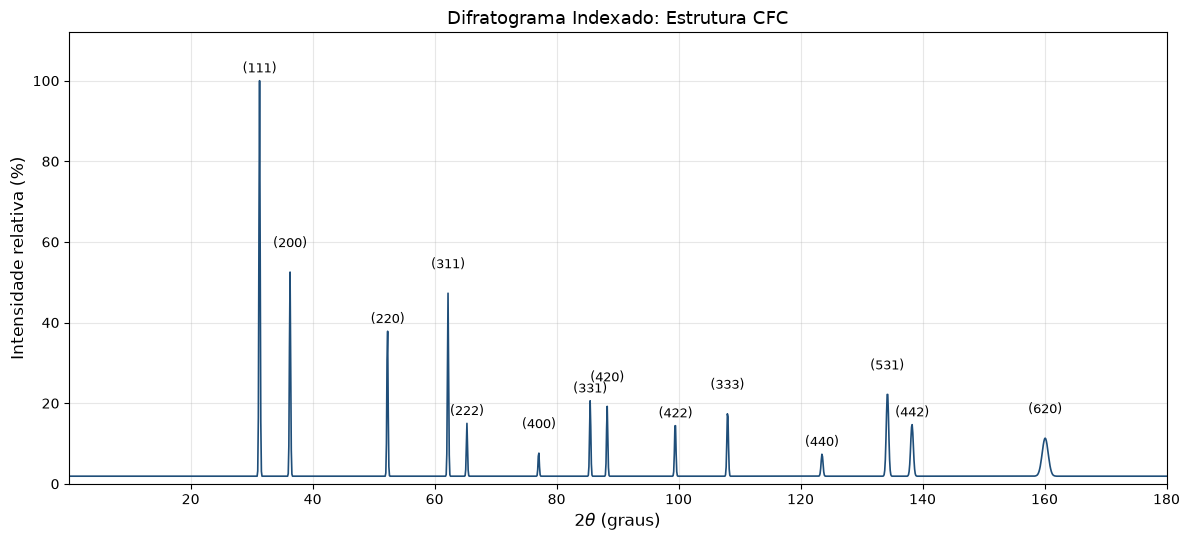

In [20]:
fig, ax = plt.subplots(figsize=(12, 5.5))
ax.plot(x, y_norm, color="#1f4e79", lw=1.2)   # curva normalizada

# Escreve o (hkl) sobre cada pico. Se houver dois planos para o mesmo pico
# (ex.: "(333) / (511)"), split(" / ")[0] pega apenas o primeiro para o rótulo.
for k, p in enumerate(picos):
    dy = 6 if k % 2 == 0 else 18                  # alterna a altura para não sobrepor
    ax.annotate(tabela["(hkl)"].iloc[k].split(" / ")[0], xy=(x[p], y_norm[p]),
                xytext=(0, dy), textcoords="offset points", ha="center", fontsize=9)

ax.set_xlabel(r"$2\theta$ (graus)", fontsize=12)
ax.set_ylabel("Intensidade relativa (%)", fontsize=12)
ax.set_title(f"Difratograma Indexado: Estrutura {estrutura}", fontsize=13)
ax.set_xlim(x.min(), x.max())
ax.set_ylim(0, 112)
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig("difratograma_indexado.png", dpi=300)   # figura para o relatório
plt.show()